# Week 3 — Advanced Data Analysis and Visualization

**Author:** Subhajit Sangram

All paths are relative to the project root. Run from the repository root.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("data/week3_4_analysis_logistics.csv", parse_dates=["order_date"])
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,2000,2000,ORD101487,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2000,NaN,NaN,NaN,2025-06-29 20:39:50.399999744,2025-01-01 00:00:00,2025-03-29 00:00:00,2025-06-24 00:00:00,2025-10-01 06:00:00,2025-12-31 00:00:00,NaN
state,2000,8,West Bengal,311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,2000,24,Nagpur,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2000,7,Home & Kitchen,344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transport_mode,2000,3,Van,887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipment_volume,2000.0,NaN,NaN,NaN,6.015,1.0,4.0,6.0,7.0,15.0,2.299221
weight_kg,2000.0,NaN,NaN,NaN,2.46745,0.22,1.3375,2.01,3.0,17.3,1.742381
distance_km,2000.0,NaN,NaN,NaN,82.41455,3.0,42.7,71.4,109.025,450.0,53.919405
fuel_price_per_litre,2000.0,NaN,NaN,NaN,95.80891,83.07,90.6075,96.475,100.8625,108.0,5.833176


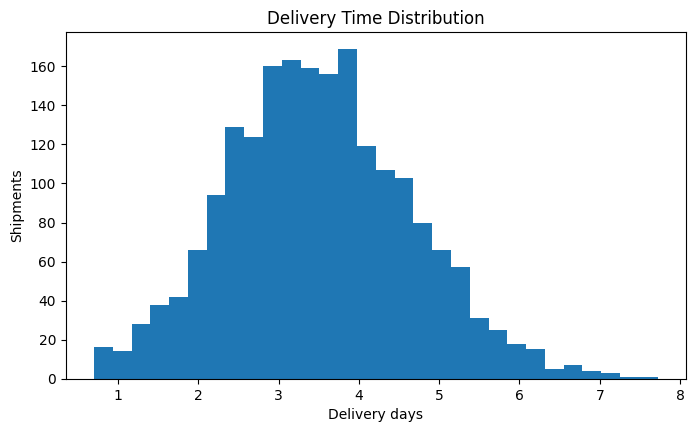

In [2]:
# Distribution
plt.figure(figsize=(8,4.5))
plt.hist(df["delivery_days"], bins=30)
plt.xlabel("Delivery days")
plt.ylabel("Shipments")
plt.title("Delivery Time Distribution")
plt.show()

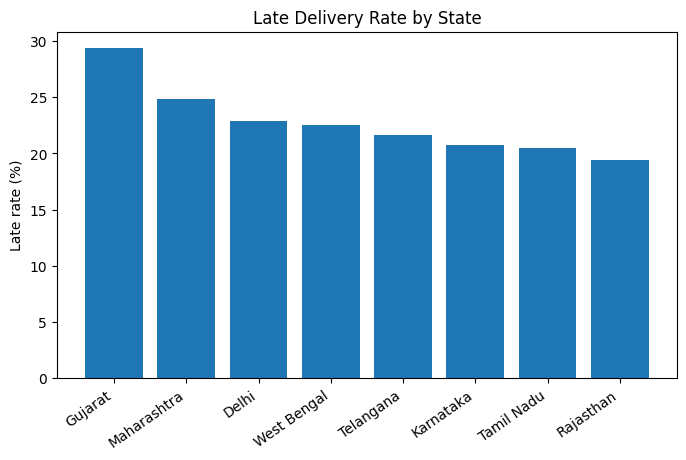

In [3]:
# Regional late rate
late_rate = df.groupby("state")["late_flag"].mean().sort_values(ascending=False) * 100
plt.figure(figsize=(8,4.5))
plt.bar(late_rate.index, late_rate.values)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Late rate (%)")
plt.title("Late Delivery Rate by State")
plt.show()

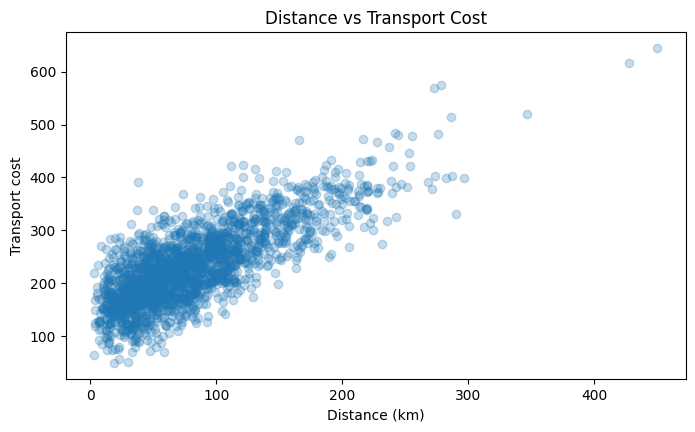

In [4]:
# Cost relationship
plt.figure(figsize=(8,4.5))
plt.scatter(df["distance_km"], df["transport_cost"], alpha=0.25)
plt.xlabel("Distance (km)")
plt.ylabel("Transport cost")
plt.title("Distance vs Transport Cost")
plt.show()

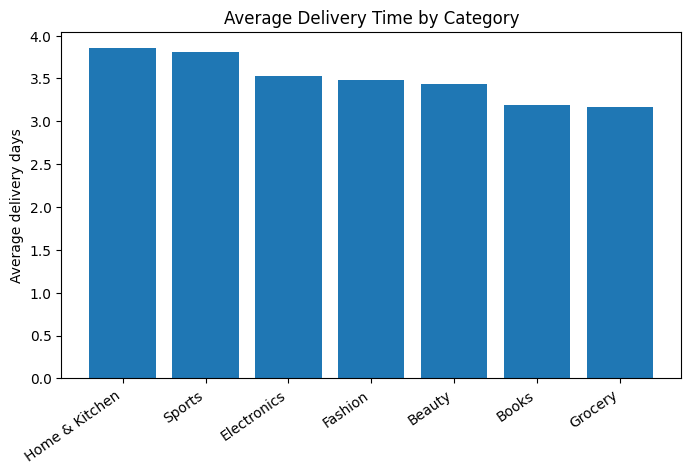

In [5]:
# Category comparison
category_avg = df.groupby("category")["delivery_days"].mean().sort_values(ascending=False)
plt.figure(figsize=(8,4.5))
plt.bar(category_avg.index, category_avg.values)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Average delivery days")
plt.title("Average Delivery Time by Category")
plt.show()

In [6]:
num_cols = ["shipment_volume","weight_kg","distance_km","delivery_days",
            "freight_cost","transport_cost","inventory_level","customer_rating"]
corr = df[num_cols].corr()
display(corr.round(2))

,shipment_volume,weight_kg,distance_km,delivery_days,freight_cost,transport_cost,inventory_level,customer_rating
shipment_volume,1.00,-0.04,0.01,0.29,0.42,0.48,0.25,0.04
weight_kg,-0.04,1.00,-0.02,0.00,0.11,0.08,0.03,-0.02
distance_km,0.01,-0.02,1.00,0.24,0.81,0.78,-0.50,0.02
delivery_days,0.29,0.00,0.24,1.00,0.32,0.34,-0.01,0.02
freight_cost,0.42,0.11,0.81,0.32,1.00,0.97,-0.29,0.01
transport_cost,0.48,0.08,0.78,0.34,0.97,1.00,-0.26,0.01
inventory_level,0.25,0.03,-0.50,-0.01,-0.29,-0.26,1.00,0.01
customer_rating,0.04,-0.02,0.02,0.02,0.01,0.01,0.01,1.00
